# Classification with full pipeline and detailed code explanation on a real data

## Step 0: Setup the imports

Each line brings in a tool under a short name.

- `import pandas as pd`, `numpy as np`, `matplotlib.pyplot as plt`: load the three libraries with nicknames, so we type `pd` instead of `pandas`.
- `from sklearn.model_selection import train_test_split`: the function that splits data into a training part and a test part.
- `from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree`: the tree model plus two ways to view a tree.
- `from sklearn.naive_bayes import CategoricalNB, GaussianNB`: the two Naive Bayes variants (categorical features vs numeric).
- `from sklearn.metrics import ...`: the scoring tools (accuracy, confusion matrix, full report).
- `pd.set_option("display.max_columns", None)`: a display setting so pandas never hides columns when printing a wide table.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.naive_bayes import CategoricalNB, GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

ETSU_NAVY = "#00053E"
ETSU_GOLD = "#FFC72C"
pd.set_option("display.max_columns", None)
print("Libraries loaded.")

Libraries loaded.


## Step 1: Load and peek

- `pd.read_csv("data/churn.csv")`: reads a CSV off disk into a DataFrame; the path is relative to this notebook.
- `df.shape`: an **attribute** giving `(rows, columns)`.
- `df.head()`: returns the first 5 rows to eyeball.

In [9]:
df = pd.read_csv("data/churn.csv")
print("Shape:", df.shape)
df.head()

Shape: (1000, 8)


,customer_id,tenure_months,contract,internet_service,tech_support,payment_method,monthly_charges,churn
0,1001,47,One year,DSL,No,Credit card,55.66,No
1,1002,52,Month-to-month,Fiber optic,Yes,Bank transfer,85.36,Yes
2,1003,20,Two year,DSL,No,Electronic check,44.86,No
3,1004,26,One year,DSL,NaN,Bank transfer,42.33,No
4,1005,69,Month-to-month,Fiber optic,Yes,Electronic check,89.52,No


## Step 2: Explore the columns and the class balance

- `df.info()`: prints each column's name, non-missing count, and data type.
- `df["churn"].value_counts()`: counts how many times each value appears.
- `(df["churn"] == "Yes")`: a comparison returning a **True/False Series**, one per row.
- `.mean()` on True/False: the **proportion trick**. True counts as 1 and False as 0, so the mean is the fraction of "Yes", the churn rate.
- `round(..., 3)`: rounds to 3 decimals.

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       1000 non-null   int64  
 1   tenure_months     1000 non-null   int64  
 2   contract          1000 non-null   str    
 3   internet_service  1000 non-null   str    
 4   tech_support      950 non-null    str    
 5   payment_method    1000 non-null   str    
 6   monthly_charges   960 non-null    float64
 7   churn             1000 non-null   str    
dtypes: float64(1), int64(2), str(5)
memory usage: 62.6 KB


In [11]:
counts = df["churn"].value_counts()
print(counts)
print("\nChurn rate:", round((df["churn"] == "Yes").mean(), 3))

churn
No     771
Yes    229
Name: count, dtype: int64

Churn rate: 0.229


**Look closer at the True/False mean.** This trick comes back several times, so prove it
to yourself on a tiny example.

In [12]:
demo = pd.Series(["Yes", "No", "Yes", "Yes"])
print("as True/False:", (demo == "Yes").tolist())   # [True, False, True, True]
print("as 1/0 summed:", (demo == "Yes").sum())        # 3
print("mean = fraction True:", (demo == "Yes").mean())# 0.75

as True/False: [True, False, True, True]
as 1/0 summed: 3
mean = fraction True: 0.75


## Step 3: Visualization 
### Step 3.1 Two quick charts  (contains a lambda)

- `plt.subplots(1, 2, figsize=(12, 4))`: a figure with 1 row and 2 side-by-side plots; `figsize` is width, height in inches. Returns the figure and an array `axes` of the two plot areas.
- `df.groupby("contract")`: splits rows into groups, one per contract value.
- `["churn"]`: within each group, keep just the churn column.
- `.apply(lambda s: (s == "Yes").mean())`: run a function on each group's churn Series.
  - `s` is one group's churn values; `(s == "Yes").mean()` is that group's churn rate (the proportion trick again, per group).
- `.plot(kind="bar", ax=axes[0], color=ETSU_NAVY)`: a bar chart; `ax=` puts it in the left plot, `color=` sets the bar color.
- `.set_title(...)`, `.set_ylabel(...)`: label the plot and its y-axis.
- `.tick_params(axis="x", rotation=20)`: tilt the x labels so they do not overlap.
- `axes[1].hist(values, bins=20, alpha=0.7, label=..., color=...)`: a histogram; `bins` is bar count, `alpha` is see-through-ness so the two overlap readably, `label` names the series.
- `df.loc[df["churn"] == label, "tenure_months"]`: `.loc` selects by label; before the comma is a True/False **row filter**, after it is the **column** to keep. So: tenure values for just churners, then just non-churners.
- `.legend(...)`, `plt.tight_layout()`, `plt.show()`: the color key, auto-spacing, and render.

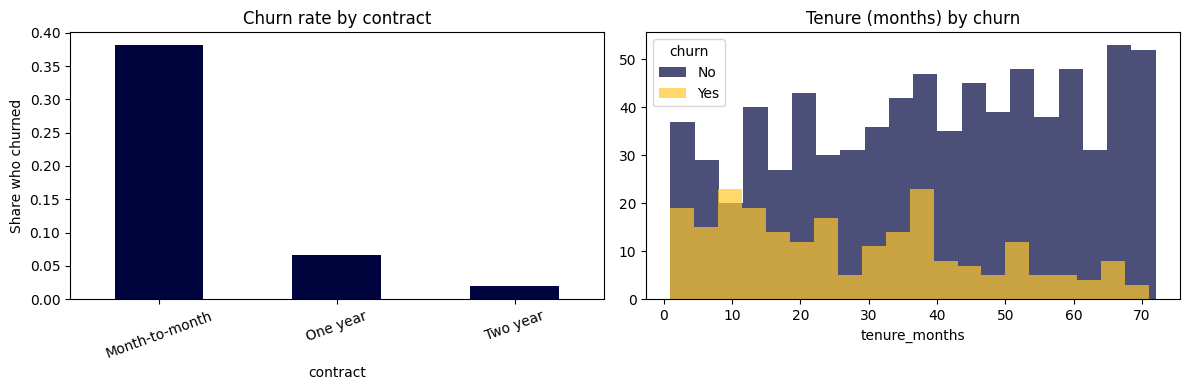

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

rate_by_contract = df.groupby("contract")["churn"].apply(lambda s: (s == "Yes").mean())
rate_by_contract.plot(kind="bar", ax=axes[0], color=ETSU_NAVY)
axes[0].set_title("Churn rate by contract")
axes[0].set_ylabel("Share who churned")
axes[0].tick_params(axis="x", rotation=20)

for label, color in [("No", ETSU_NAVY), ("Yes", ETSU_GOLD)]:
    axes[1].hist(df.loc[df["churn"] == label, "tenure_months"], bins=20,
                 alpha=0.7, label=label, color=color)
axes[1].set_title("Tenure (months) by churn")
axes[1].set_xlabel("tenure_months")
axes[1].legend(title="churn")

plt.tight_layout()
plt.show()

#### Step 3.2: **Look closer at groupby + the lambda.** Before plotting, print the grouped numbers so you
see what the bars are drawn from.

In [14]:
# groupby splits the rows; the lambda computes each group's churn rate
print(df.groupby("contract")["churn"].apply(lambda s: (s == "Yes").mean()).round(3))
print("\nFor comparison, how many rows are in each contract group:")
print(df.groupby("contract").size())

contract
Month-to-month    0.382
One year          0.066
Two year          0.020
Name: churn, dtype: float64

For comparison, how many rows are in each contract group:
contract
Month-to-month    545
One year          258
Two year          197
dtype: int64


## Step 4: Preprocess
### Step 4.1: Drop ID and fill missing values

- `df.drop(columns=["customer_id"])`: returns a copy without that column (`columns=` means a column, not a row).
- `.copy()`: an independent copy, so edits do not touch the original `df`.
- `for col in data.columns`: loop over every column name.
- `pd.api.types.is_numeric_dtype(data[col])`: True if the column holds numbers; we use it to choose the fill method.
- `data[col].fillna(data[col].median())`: `fillna` replaces missing values; `median()` is the middle value (numeric fill).
- `data[col].fillna(data[col].mode()[0])`: `mode()` returns the most common value(s) as a **Series**, so `[0]` takes the top one (text fill).
- `data.isna().sum().sum()`: `isna()` makes a True/False table of missing cells; the first `.sum()` totals each column, the second `.sum()` adds those into one grand total.
- `int(...)`: a clean integer for printing.

In [15]:
data = df.drop(columns=["customer_id"]).copy()

for col in data.columns:
    if pd.api.types.is_numeric_dtype(data[col]):
        data[col] = data[col].fillna(data[col].median())
    else:
        data[col] = data[col].fillna(data[col].mode()[0])

print("Missing values remaining:", int(data.isna().sum().sum()))

Missing values remaining: 0


**Look closer at `.mode()[0]`.** `mode()` can return several values (ties), so it always
returns a Series; `[0]` takes the first.

In [16]:
print("mode() returns a Series:")
print(df["contract"].mode())
print("\nmode()[0] takes the top value:", df["contract"].mode()[0])

mode() returns a Series:
0    Month-to-month
Name: contract, dtype: str

mode()[0] takes the top value: Month-to-month


### Step 4.2: Split off the target and one-hot encode

- `data["churn"]`: pull the target column into `y`.
- `data.drop(columns=["churn"])`: everything except the target becomes the features.
- `pd.get_dummies(features, drop_first=True)`: **one-hot encoding**. Each text column becomes 0/1 indicator columns, one per category. `drop_first=True` drops one category from each (if it is not the others, it is the dropped one) to avoid redundancy.
- `list(X.columns)`: the new column names, as a list.

In [17]:
y = data["churn"]
features = data.drop(columns=["churn"])
X = pd.get_dummies(features, drop_first=True)
print(list(X.columns))
X.head()

['tenure_months', 'monthly_charges', 'contract_One year', 'contract_Two year', 'internet_service_Fiber optic', 'internet_service_No', 'tech_support_Yes', 'payment_method_Credit card', 'payment_method_Electronic check', 'payment_method_Mailed check']


,tenure_months,monthly_charges,contract_One year,contract_Two year,internet_service_Fiber optic,internet_service_No,tech_support_Yes,payment_method_Credit card,payment_method_Electronic check,payment_method_Mailed check
0,47,55.66,True,False,False,False,False,True,False,False
1,52,85.36,False,False,True,False,True,False,False,False
2,20,44.86,False,True,False,False,False,False,True,False
3,26,42.33,True,False,False,False,False,False,False,False
4,69,89.52,False,False,True,False,True,False,True,False


**Look closer at get_dummies.** Watch one text column turn into indicator columns, and see
what `drop_first` does.

In [18]:
tiny = pd.DataFrame({"internet_service": ["DSL", "Fiber optic", "No", "DSL"]})
print("Original:\n", tiny, "\n")
print("get_dummies (keep all categories):\n", pd.get_dummies(tiny), "\n")
print("get_dummies(drop_first=True) drops one column:\n", pd.get_dummies(tiny, drop_first=True))

Original:
   internet_service
0              DSL
1      Fiber optic
2               No
3              DSL 

get_dummies (keep all categories):
    internet_service_DSL  internet_service_Fiber optic  internet_service_No
0                  True                         False                False
1                 False                          True                False
2                 False                         False                 True
3                  True                         False                False 

get_dummies(drop_first=True) drops one column:
    internet_service_Fiber optic  internet_service_No
0                         False                False
1                          True                False
2                         False                 True
3                         False                False


## Step 5: Split into training and test sets

- `train_test_split(X, y, test_size=0.25, random_state=1, stratify=y)`: `test_size=0.25` holds out 25% for testing; `random_state=1` fixes the shuffle; `stratify=y` keeps the same churn rate in both halves. Returns four pieces in this order: `X_train, X_test, y_train, y_test`.
- `X_train.shape[0]`: `.shape` is `(rows, columns)`, so `[0]` is the row count.

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=1, stratify=y)
print("Training rows:", X_train.shape[0], " Test rows:", X_test.shape[0])

Training rows: 750  Test rows: 250


## Step 6: Decision tree - train and evaluate

- `DecisionTreeClassifier(max_depth=5, random_state=1)`: a tree capped at depth 5 so it does not overfit by growing endlessly.
- `.fit(X_train, y_train)` then `.predict(X_test)`: learn on the training half, predict on the unseen test half.
- `accuracy_score(y_test, dt_pred)`: fraction of test rows predicted correctly.
- `ConfusionMatrixDisplay.from_predictions(y_test, dt_pred, cmap="Blues")`: builds and draws the confusion matrix (TP, TN, FP, FN) from the true and predicted labels; `cmap` is the color scheme.
- `classification_report(y_test, dt_pred)`: precision, recall, and F1 per class in one table.

Decision tree accuracy: 0.832


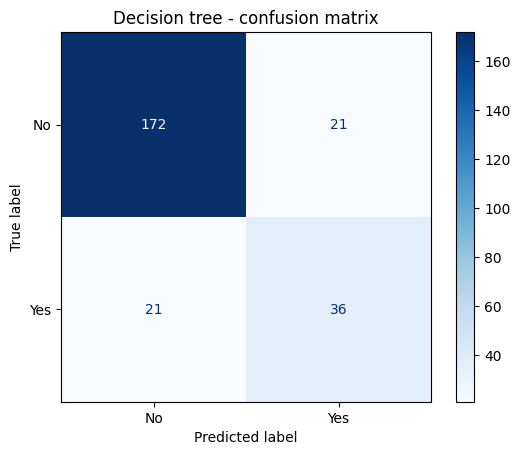

              precision    recall  f1-score   support

          No       0.89      0.89      0.89       193
         Yes       0.63      0.63      0.63        57

    accuracy                           0.83       250
   macro avg       0.76      0.76      0.76       250
weighted avg       0.83      0.83      0.83       250



In [20]:
dtree = DecisionTreeClassifier(max_depth=5, random_state=1)
dtree.fit(X_train, y_train)
dt_pred = dtree.predict(X_test)

print("Decision tree accuracy:", round(accuracy_score(y_test, dt_pred), 3))
ConfusionMatrixDisplay.from_predictions(y_test, dt_pred, cmap="Blues")
plt.title("Decision tree - confusion matrix")
plt.show()
print(classification_report(y_test, dt_pred))

## Step 7: Naive Bayes - train and evaluate

Identical pattern, different model. Our features are now a mix of counts and 0/1 indicators,
so we use `GaussianNB` (general-purpose Naive Bayes). Only the model name changes; `fit`,
`predict`, and the three scoring tools are exactly as above.

Naive Bayes accuracy: 0.8


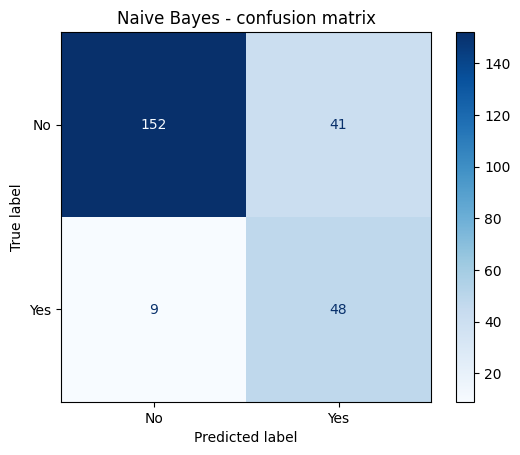

              precision    recall  f1-score   support

          No       0.94      0.79      0.86       193
         Yes       0.54      0.84      0.66        57

    accuracy                           0.80       250
   macro avg       0.74      0.81      0.76       250
weighted avg       0.85      0.80      0.81       250



In [21]:
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)
nb_pred = nb_model.predict(X_test)

print("Naive Bayes accuracy:", round(accuracy_score(y_test, nb_pred), 3))
ConfusionMatrixDisplay.from_predictions(y_test, nb_pred, cmap="Blues")
plt.title("Naive Bayes - confusion matrix")
plt.show()
print(classification_report(y_test, nb_pred))

## Step 8: Compare the two against a baseline

- `(y_test == "No").mean()`: the proportion trick again, the accuracy of always guessing "No".
- `pd.Series({...})`: a small labeled list of the three scores.
- `.round(3)`: rounds for display.
- `.plot(kind="bar", color=[...])`: one bar per model; `color=` takes a **list** so each bar gets its own color.
- `plt.ylim(0, 1)`: fixes the y-axis from 0 to 1 so the bars are not visually exaggerated.

Baseline (always No)    0.772
Decision tree           0.832
Naive Bayes             0.800
dtype: float64


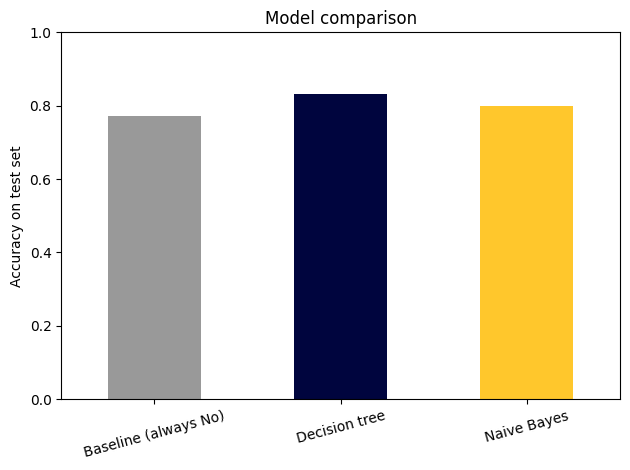

In [22]:
baseline = (y_test == "No").mean()
scores = pd.Series({"Baseline (always No)": baseline,
                    "Decision tree": accuracy_score(y_test, dt_pred),
                    "Naive Bayes": accuracy_score(y_test, nb_pred)})
print(scores.round(3))

scores.plot(kind="bar", color=["#999999", ETSU_NAVY, ETSU_GOLD])
plt.ylabel("Accuracy on test set")
plt.title("Model comparison")
plt.ylim(0, 1)
plt.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

# The pattern to remember

Every sklearn model follows the same four steps:

1. `Model(...)` to create it.
2. `.fit(X_train, y_train)` to learn.
3. `.predict(X_test)` to classify new rows.
4. `accuracy_score` / `ConfusionMatrixDisplay` / `classification_report` to grade it.

Everything else in this notebook is getting the data into shape so those four steps can run.